# Tugas 1 - Klasifikasi Jamur dengan Naive Bayes

| Nama | NRP |
|------|-----|
| Ahmad Zaki Fauzan Nabil | 5054251044 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Mushroom Dataset dari UCI Machine Learning Repository.

Dataset dapat diakses melalui:
- https://www.kaggle.com/datasets/uciml/mushroom-classification

Untuk metadata / penjelasan mengenai dataset bisa mengakses link berikut:
- https://archive.ics.uci.edu/dataset/73/mushroom

Tujuan utama dari tugas ini adalah membangun dan membandingkan tiga varian Naive Bayes, yaitu Categorical NB, Bernoulli NB, dan Multinomial NB, untuk mengklasifikasikan apakah suatu jamur dapat dimakan (edible) atau beracun (poisonous).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan untuk masing-masing varian Naive Bayes.
3. Eksperimen Model
   - Bangun model Categorical NB, Bernoulli NB, dan Multinomial NB.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, dll)
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.naive_bayes import CategoricalNB, BernoulliNB, MultinomialNB
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    roc_curve
)

# Pengaturan visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

In [2]:
# Load dataset dan tampilkan beberapa baris pertama.
# Semua nilai pada dataset berupa single character yang merupakan kode singkatan dari kategori.
# Contoh: pada kolom class, e = edible dan p = poisonous.
df = pd.read_csv("mushrooms.csv")
df.head()

,class,cap-shape,cap-surface,cap-color,bruises,odor,gill-attachment,gill-spacing,gill-size,gill-color,...,stalk-surface-below-ring,stalk-color-above-ring,stalk-color-below-ring,veil-type,veil-color,ring-number,ring-type,spore-print-color,population,habitat
0,p,x,s,n,t,p,f,c,n,k,...,s,w,w,p,w,o,p,k,s,u
1,e,x,s,y,t,a,f,c,b,k,...,s,w,w,p,w,o,p,n,n,g
2,e,b,s,w,t,l,f,c,b,n,...,s,w,w,p,w,o,p,n,n,m
3,p,x,y,w,t,p,f,c,n,n,...,s,w,w,p,w,o,p,k,s,u
4,e,x,s,g,f,n,f,w,b,k,...,s,w,w,p,w,o,e,n,a,g


In [3]:
# Tampilkan informasi dasar dataset: jumlah baris dan kolom, tipe data, dan jumlah missing value.
# Perhatikan kolom stalk-root yang memiliki nilai '?' sebagai representasi missing value.
print(f"Dimensi dataset: {df.shape[0]} baris, {df.shape[1]} kolom\n")
print("Informasi umum tipe data:")
df.info()

print("\nJumlah nilai null standar:")
print(df.isnull().sum())

print("\nJumlah nilai '?' pada kolom:")
missing_char = (df == '?').sum()
print(missing_char[missing_char > 0])

Dimensi dataset: 8124 baris, 23 kolom

Informasi umum tipe data:
<class 'pandas.DataFrame'>
RangeIndex: 8124 entries, 0 to 8123
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype
---  ------                    --------------  -----
 0   class                     8124 non-null   str  
 1   cap-shape                 8124 non-null   str  
 2   cap-surface               8124 non-null   str  
 3   cap-color                 8124 non-null   str  
 4   bruises                   8124 non-null   str  
 5   odor                      8124 non-null   str  
 6   gill-attachment           8124 non-null   str  
 7   gill-spacing              8124 non-null   str  
 8   gill-size                 8124 non-null   str  
 9   gill-color                8124 non-null   str  
 10  stalk-shape               8124 non-null   str  
 11  stalk-root                8124 non-null   str  
 12  stalk-surface-above-ring  8124 non-null   str  
 13  stalk-surface-below-ring  8124 non-null

In [4]:
# Tampilkan jumlah nilai unik pada setiap fitur.
# Perhatikan variasi jumlah kategori antar fitur, misalnya veil-type hanya punya 1 nilai unik.
print("Jumlah nilai unik per kolom:")
print(df.nunique())

Jumlah nilai unik per kolom:
class                        2
cap-shape                    6
cap-surface                  4
cap-color                   10
bruises                      2
odor                         9
gill-attachment              2
gill-spacing                 2
gill-size                    2
gill-color                  12
stalk-shape                  2
stalk-root                   5
stalk-surface-above-ring     4
stalk-surface-below-ring     4
stalk-color-above-ring       9
stalk-color-below-ring       9
veil-type                    1
veil-color                   4
ring-number                  3
ring-type                    5
spore-print-color            9
population                   6
habitat                      7
dtype: int64


Jumlah sampel per kelas:
class
e    4208
p    3916
Name: count, dtype: int64

Persentase per kelas (%):
class
e    51.8
p    48.2
Name: proportion, dtype: float64


C:\Users\ahmad\AppData\Local\Temp\ipykernel_17428\2924510553.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.countplot(x='class', data=df, palette='Set2')


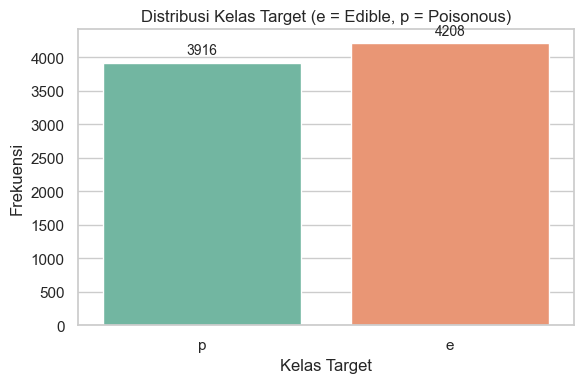

In [5]:
# Tampilkan distribusi kelas target (class) dalam bentuk bar plot.
# Perhatikan apakah dataset ini imbalanced.
print("Jumlah sampel per kelas:")
print(df['class'].value_counts())
print("\nPersentase per kelas (%):")
print((df['class'].value_counts(normalize=True) * 100).round(2))

plt.figure(figsize=(6, 4))
ax = sns.countplot(x='class', data=df, palette='Set2')
plt.title("Distribusi Kelas Target (e = Edible, p = Poisonous)")
plt.xlabel("Kelas Target")
plt.ylabel("Frekuensi")

for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='bottom', fontsize=10, 
                xytext=(0, 4), textcoords='offset points')

plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

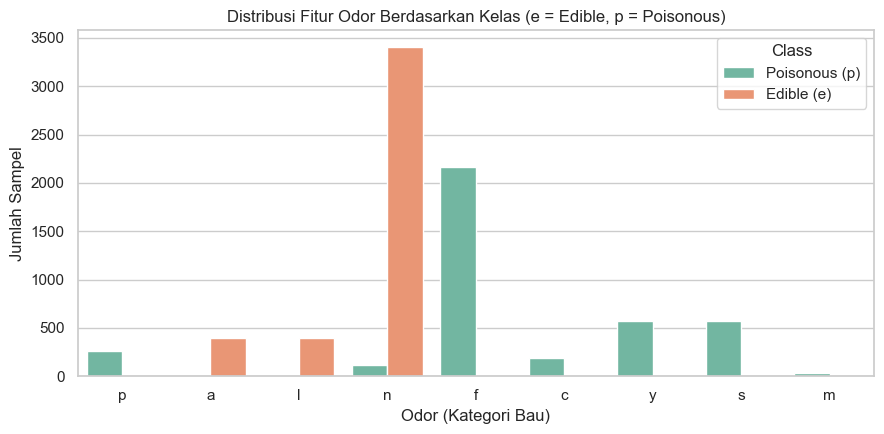

Tabel silang (crosstab) antara odor dan kelas target:
class     e     p   All
odor                   
a       400     0   400
c         0   192   192
f         0  2160  2160
l       400     0   400
m         0    36    36
n      3408   120  3528
p         0   256   256
s         0   576   576
y         0   576   576
All    4208  3916  8124


In [6]:
# EDA tambahan: Analisis hubungan antara fitur odor (bau) dan kelas jamur
# Fitur odor sering kali menjadi pembeda kuat antara jamur beracun dan jamur yang dapat dimakan.
plt.figure(figsize=(9, 4.5))
sns.countplot(x='odor', hue='class', data=df, palette='Set2')
plt.title("Distribusi Fitur Odor Berdasarkan Kelas (e = Edible, p = Poisonous)")
plt.xlabel("Odor (Kategori Bau)")
plt.ylabel("Jumlah Sampel")
plt.legend(title="Class", labels=["Poisonous (p)", "Edible (e)"])
plt.tight_layout()
plt.show()

print("Tabel silang (crosstab) antara odor dan kelas target:")
print(pd.crosstab(df['odor'], df['class'], margins=True))

# 2. Preprocessing

Karena semua fitur bertipe kategorikal, setiap varian Naive Bayes membutuhkan representasi data yang berbeda:

| Model | Representasi yang dibutuhkan | Preprocessing |
|---|---|---|
| Categorical NB | Integer per kategori | OrdinalEncoder |
| Bernoulli NB | Binary 0/1 per kategori | LabelBinarizer / OneHotEncoder |
| Multinomial NB | Count / frekuensi non-negatif | OneHotEncoder |

In [7]:
# Tangani missing value pada kolom stalk-root (nilai '?').
# Pilih strategi yang sesuai: drop baris, ganti dengan modus, atau jadikan kategori tersendiri.

# Kita memperlakukan '?' sebagai kategori tersendiri ('missing').
# Alasan: proporsi '?' mencapai ~30.5% (2.480 sampel), sehingga jika dihapus akan membuang terlalu banyak data,
# dan jika diganti modus akan membiaskan frekuensi kategori 'b' secara berlebihan.
df['stalk-root'] = df['stalk-root'].replace('?', 'missing')

print("Distribusi kategori stalk-root setelah penanganan:")
print(df['stalk-root'].value_counts())

Distribusi kategori stalk-root setelah penanganan:
stalk-root
b          3776
missing    2480
e          1120
c           556
r           192
Name: count, dtype: int64


In [8]:
# Periksa apakah ada fitur yang hanya memiliki satu nilai unik.
# Fitur seperti itu tidak memberikan informasi apapun dan sebaiknya di-drop.

single_val_cols = [col for col in df.columns if df[col].nunique() == 1]
print(f"Fitur konstan (hanya 1 nilai unik): {single_val_cols}")

df = df.drop(columns=single_val_cols)
print(f"Jumlah kolom setelah fitur konstan di-drop: {df.shape[1]}")

Fitur konstan (hanya 1 nilai unik): ['veil-type']
Jumlah kolom setelah fitur konstan di-drop: 22


In [9]:
# Pisahkan fitur (X) dan target (y).
# Encode target: e = 0 (edible), p = 1 (poisonous).
# Bagi data menjadi train set dan test set (misalnya 80:20).
# Gunakan stratify=y agar distribusi kelas tetap proporsional.

X = df.drop(columns=['class'])
y = df['class'].map({'e': 0, 'p': 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Dimensi X_train: {X_train.shape}, X_test: {X_test.shape}")
print(f"Dimensi y_train: {y_train.shape}, y_test: {y_test.shape}")
print("\nProporsi kelas target pada train set:")
print(y_train.value_counts(normalize=True).round(4))
print("\nProporsi kelas target pada test set:")
print(y_test.value_counts(normalize=True).round(4))

Dimensi X_train: (6499, 21), X_test: (1625, 21)
Dimensi y_train: (6499,), y_test: (1625,)

Proporsi kelas target pada train set:
class
0    0.5179
1    0.4821
Name: proportion, dtype: float64

Proporsi kelas target pada test set:
class
0    0.5182
1    0.4818
Name: proportion, dtype: float64


In [10]:
# Preprocessing untuk Categorical NB:
# Gunakan OrdinalEncoder untuk mengubah setiap kategori menjadi integer.
# Contoh: cap-shape b=0, c=1, f=2, k=3, s=4, x=5
# Fit hanya pada train set, transform pada train set dan test set.

oe = OrdinalEncoder()
X_train_oe = oe.fit_transform(X_train)
X_test_oe = oe.transform(X_test)

print("Contoh 3 baris pertama X_train setelah OrdinalEncoder:")
print(X_train_oe[:3])

Contoh 3 baris pertama X_train setelah OrdinalEncoder:
[[ 2.  3.  9.  0.  2.  1.  0.  0.  2.  0.  0.  1.  1.  6.  0.  2.  1.  2.
   1.  5.  1.]
 [ 5.  2.  5.  1.  5.  1.  0.  0.  1.  0.  3.  2.  2.  2.  7.  2.  2.  0.
   7.  1.  6.]
 [ 0.  2.  3.  0.  5.  1.  1.  0. 10.  0.  3.  1.  2.  7.  7.  2.  2.  4.
   7.  3.  1.]]


In [11]:
# Preprocessing untuk Bernoulli NB dan Multinomial NB:
# Gunakan OneHotEncoder untuk mengubah setiap kategori menjadi representasi binary.
# Hasilnya berupa matriks sparse dengan nilai 0 dan 1.
# Fit hanya pada train set, transform pada train set dan test set.

ohe = OneHotEncoder(sparse_output=True, handle_unknown='ignore')
X_train_ohe = ohe.fit_transform(X_train)
X_test_ohe = ohe.transform(X_test)

print(f"Dimensi X_train_ohe (sparse): {X_train_ohe.shape}")
print(f"Dimensi X_test_ohe (sparse): {X_test_ohe.shape}")
print(f"Tipe struktur data: {type(X_train_ohe)}")

Dimensi X_train_ohe (sparse): (6499, 116)
Dimensi X_test_ohe (sparse): (1625, 116)
Tipe struktur data: <class 'scipy.sparse._csr.csr_matrix'>


# 3. Eksperimen Model

## 3.1 Categorical Naive Bayes

CategoricalNB adalah varian yang paling sesuai untuk dataset ini karena semua fitur memang bertipe kategorikal. Model menghitung P(fitur=kategori | kelas) secara langsung untuk setiap kategori pada setiap fitur.

In [12]:
# Inisialisasi dan latih model CategoricalNB menggunakan train set hasil OrdinalEncoder.
model_cnb = CategoricalNB()
model_cnb.fit(X_train_oe, y_train)

,"alpha alpha: float, default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"min_categories min_categories: int or array-like of shape (n_features,), default=NoneMinimum number of categories per feature.- integer: Sets the minimum number of categories per feature to `n_categories` for each features.- array-like: shape (n_features,) where `n_categories[i]` holds the minimum number of categories for the ith column of the input.- None (default): Determines the number of categories automatically from the training data... versionadded:: 0.24",None
Name,Type,Value
"category_count_ category_count_: list of arrays of shape (n_features,)Holds arrays of shape (n_classes, n_categories of respective feature)for each feature. Each array provides the number of samplesencountered for each class and category of the specific feature.",list,"[array([[ 324.... 0., 1382.]]), array([[1248....134., 1368.]]), array([[ 38.... 542.]]), array([[1161....634., 499.]]), ...]"
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[3366.,3133.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.66,-0.73]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_log_prob_ feature_log_prob_: list of arrays of shape (n_features,)Holds arrays of shape (n_classes, n_categories of respective feature)for each feature. Each array provides the empirical log probabilityof categories given the respective feature and class, ``P(x_i|y)``.",list,"[array([[-2.33...-0.81964923]]), array([[-0.99...-0.82918638]]), array([[-4.46...-1.75582372]]), array([[-1.06...-1.83577635]]), ...]"


In [13]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.
y_pred_cnb = model_cnb.predict(X_test_oe)
y_prob_cnb = model_cnb.predict_proba(X_test_oe)[:, 1]

print("Contoh 5 hasil prediksi label (Categorical NB):", y_pred_cnb[:5])
print("Contoh 5 hasil prediksi probabilitas (kelas 1):", np.round(y_prob_cnb[:5], 4))

Contoh 5 hasil prediksi label (Categorical NB): [1 0 0 1 1]
Contoh 5 hasil prediksi probabilitas (kelas 1): [1.     0.3692 0.     1.     1.    ]


## 3.2 Bernoulli Naive Bayes

BernoulliNB bekerja pada representasi binary. Dengan OneHotEncoder, setiap kategori menjadi kolom tersendiri bernilai 0 atau 1, sehingga model memperlakukan setiap kategori sebagai fitur binary ada/tidak ada.

In [14]:
# Inisialisasi dan latih model BernoulliNB menggunakan train set hasil OneHotEncoder.
model_bnb = BernoulliNB()
model_bnb.fit(X_train_ohe, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"binarize binarize: float or None, default=0.0Threshold for binarizing (mapping to booleans) of sample features.If None, input is presumed to already consist of binary vectors.",0.0
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[3366.,3133.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Log probability of each class (smoothed).","ndarray[float64](2,)","[-0.66,-0.73]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 116)","[[ 324., 0.,1276.,..., 109., 80., 157.], [ 37., 4.,1241.,..., 782., 221., 0.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of features given a class, P(x_i|y).","ndarray[float64](2, 116)","[[-2.34,-8.12,-0.97,...,-3.42,-3.73,-3.06], [-4.41,-6.44,-0.93,...,-1.39,-2.65,-8.05]]"


In [15]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.
y_pred_bnb = model_bnb.predict(X_test_ohe)
y_prob_bnb = model_bnb.predict_proba(X_test_ohe)[:, 1]

print("Contoh 5 hasil prediksi label (Bernoulli NB):", y_pred_bnb[:5])
print("Contoh 5 hasil prediksi probabilitas (kelas 1):", np.round(y_prob_bnb[:5], 4))

Contoh 5 hasil prediksi label (Bernoulli NB): [1 0 0 1 1]
Contoh 5 hasil prediksi probabilitas (kelas 1): [1.     0.4069 0.     1.     1.    ]


## 3.3 Multinomial Naive Bayes

MultinomialNB membutuhkan input non-negatif dan menginterpretasikannya sebagai frekuensi. Dengan OneHotEncoder yang menghasilkan nilai 0 dan 1, model dapat menerimanya sebagai counts meskipun secara semantik tiap nilai hanya menandakan ada/tidak ada kategori.

In [16]:
# Inisialisasi dan latih model MultinomialNB menggunakan train set hasil OneHotEncoder.
model_mnb = MultinomialNB()
model_mnb.fit(X_train_ohe, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[3366.,3133.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.66,-0.73]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 116)","[[ 324., 0.,1276.,..., 109., 80., 157.], [ 37., 4.,1241.,..., 782., 221., 0.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 116)","[[ -5.38,-11.17, -4.02,..., -6.47, -6.77, -6.11], [ -7.46, -9.49, -3.97,..., -4.43, -5.69,-11.1 ]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,116


In [17]:
# Lakukan prediksi pada test set.
# Simpan hasil prediksi label dan probabilitas kelas 1 untuk keperluan evaluasi.
y_pred_mnb = model_mnb.predict(X_test_ohe)
y_prob_mnb = model_mnb.predict_proba(X_test_ohe)[:, 1]

print("Contoh 5 hasil prediksi label (Multinomial NB):", y_pred_mnb[:5])
print("Contoh 5 hasil prediksi probabilitas (kelas 1):", np.round(y_prob_mnb[:5], 4))

Contoh 5 hasil prediksi label (Multinomial NB): [1 0 0 1 1]
Contoh 5 hasil prediksi probabilitas (kelas 1): [1.     0.3692 0.     1.     1.    ]


# 4. Evaluasi Model

In [18]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score.
# Sajikan dalam satu tabel perbandingan agar mudah dibandingkan.

eval_summary = {
    "Model": ["Categorical NB", "Bernoulli NB", "Multinomial NB"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_cnb),
        accuracy_score(y_test, y_pred_bnb),
        accuracy_score(y_test, y_pred_mnb)
    ],
    "Precision": [
        precision_score(y_test, y_pred_cnb),
        precision_score(y_test, y_pred_bnb),
        precision_score(y_test, y_pred_mnb)
    ],
    "Recall": [
        recall_score(y_test, y_pred_cnb),
        recall_score(y_test, y_pred_bnb),
        recall_score(y_test, y_pred_mnb)
    ],
    "F1-Score": [
        f1_score(y_test, y_pred_cnb),
        f1_score(y_test, y_pred_bnb),
        f1_score(y_test, y_pred_mnb)
    ],
    "ROC AUC": [
        roc_auc_score(y_test, y_prob_cnb),
        roc_auc_score(y_test, y_prob_bnb),
        roc_auc_score(y_test, y_prob_mnb)
    ]
}

df_eval = pd.DataFrame(eval_summary)
df_eval.round(4)

,Model,Accuracy,Precision,Recall,F1-Score,ROC AUC
0,Categorical NB,0.9458,0.9901,0.8966,0.9410,0.9972
1,Bernoulli NB,0.9329,0.9814,0.8774,0.9265,0.9954
2,Multinomial NB,0.9458,0.9901,0.8966,0.9410,0.9972


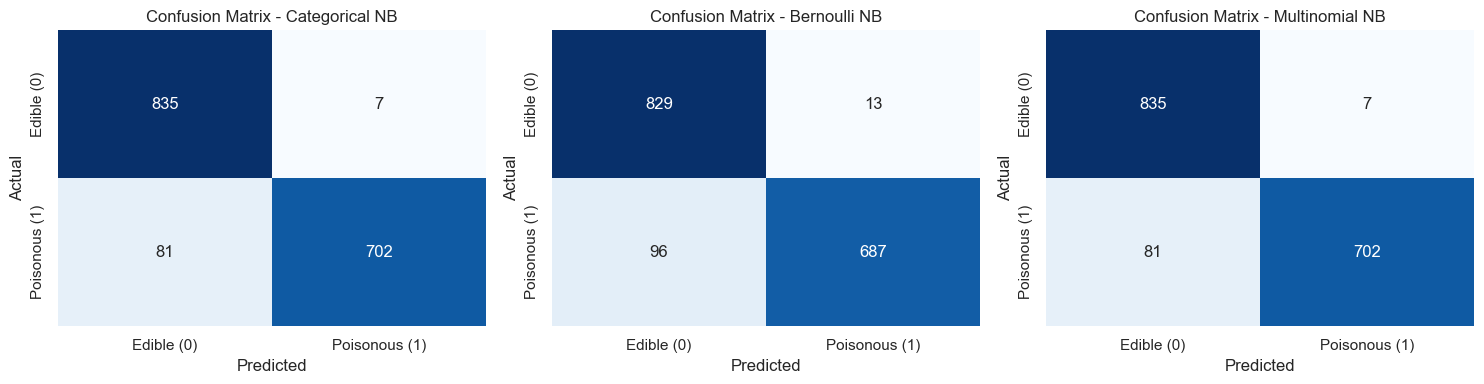

In [19]:
# Tampilkan Confusion Matrix setiap model dalam bentuk heatmap.
# Susun ketiganya dalam satu baris subplot.

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

models_eval = [
    ("Categorical NB", y_pred_cnb),
    ("Bernoulli NB", y_pred_bnb),
    ("Multinomial NB", y_pred_mnb)
]

for ax, (model_name, y_pred) in zip(axes, models_eval):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax, cbar=False,
                xticklabels=['Edible (0)', 'Poisonous (1)'],
                yticklabels=['Edible (0)', 'Poisonous (1)'])
    ax.set_title(f"Confusion Matrix - {model_name}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

plt.tight_layout()
plt.show()

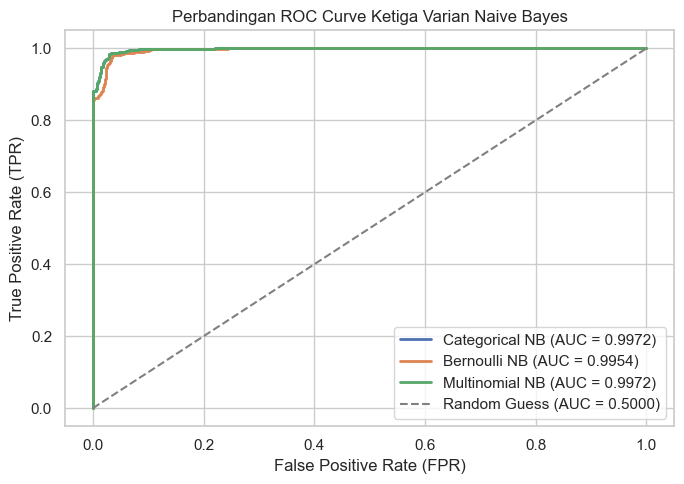

In [20]:
# Tampilkan ROC Curve ketiga model dalam satu plot beserta nilai AUC masing-masing.

plt.figure(figsize=(7, 5))

models_curve = [
    ("Categorical NB", y_prob_cnb),
    ("Bernoulli NB", y_prob_bnb),
    ("Multinomial NB", y_prob_mnb)
]

for name, y_prob in models_curve:
    fpr, tpr, _ = roc_curve(y_test, y_prob)
    auc_score = roc_auc_score(y_test, y_prob)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc_score:.4f})")

plt.plot([0, 1], [0, 1], color='grey', linestyle='--', label="Random Guess (AUC = 0.5000)")
plt.title("Perbandingan ROC Curve Ketiga Varian Naive Bayes")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# 5. Analisis

#### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa Categorical NB, Bernoulli NB, dan Multinomial NB berdasarkan hasil evaluasi. Kaitkan perbedaan performa dengan perbedaan representasi data yang digunakan oleh masing-masing model. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

---

### Pembahasan Hasil Eksperimen

Berdasarkan eksperimen yang telah dijalankan pada dataset *Mushroom* (1.625 sampel uji pada pembagian train-test 80:20), didapatkan perbandingan hasil evaluasi sebagai berikut:

#### 1. Perbandingan Kinerja Model
| Metrik | Categorical NB | Bernoulli NB | Multinomial NB |
|---|:---:|:---:|:---:|
| **Accuracy** | **0.9458 (94.58%)** | 0.9329 (93.29%) | **0.9458 (94.58%)** |
| **Precision** | **0.9901 (99.01%)** | 0.9814 (98.14%) | **0.9901 (99.01%)** |
| **Recall** | **0.8966 (89.66%)** | 0.8774 (87.74%) | **0.8966 (89.66%)** |
| **F1-Score** | **0.9410 (94.10%)** | 0.9265 (92.65%) | **0.9410 (94.10%)** |
| **ROC AUC** | **0.9972** | 0.9954 | **0.9972** |

Secara keseluruhan, **Categorical NB dan Multinomial NB menghasilkan metrik yang persis identik**, sementara **Bernoulli NB menghasilkan performa yang sedikit lebih rendah** (terlihat penurunan pada seluruh metrik, terutama recall yang turun dari 89.66% menjadi 87.74%).

---

#### 2. Kaitan Performa dengan Representasi Data

Hasil eksperimen di atas dapat dijelaskan secara teoritis berdasarkan formulasi matematis dan representasi data masing-masing varian Naive Bayes:

1. **Categorical Naive Bayes (dengan OrdinalEncoder)**
   - *Representasi:* Fitur diubah menjadi bilangan bulat diskret $0, 1, \dots, K-1$.
   - *Karakteristik:* Model menghitung probabilitas kondisional $P(X_i = k \mid Y = c)$ secara langsung untuk setiap kategori pada setiap fitur. Karena seluruh fitur jamur adalah data kategorikal murni, representasi ini menjaga sifat multikategori asli dari fitur tanpa menambah dimensi berlebihan (tetap 21 fitur input).
   - *Hasil:* Model mampu menangkap distribusi probabilitas kategori dengan sangat baik, menghasilkan akurasi 94.58% dan AUC 0.9972.

2. **Multinomial Naive Bayes (dengan OneHotEncoder)**
   - *Representasi:* Data diubah menjadi matriks biner sparse berdimensi $1.625 	imes 117$ melalui One-Hot Encoding.
   - *Mengapa hasilnya identik dengan Categorical NB?*
     Meskipun Multinomial NB awalnya dirancang untuk data count/frekuensi diskret (seperti teks Bag-of-Words), jika diisi dengan data One-Hot bernilai 0 dan 1 di mana setiap fitur asal memiliki tepat satu nilai 1 per sampel, total frekuensi fitur per observasi bernilai konstan ($N = 21$).
     Akibatnya, formulasi estimasi parameter frekuensi pada Multinomial NB dengan Laplace smoothing ($lpha=1$) berbanding lurus secara proporsional dengan estimasi probabilitas kategori pada Categorical NB. Log-likelihood yang dihasilkan menghasilkan pemeringkatan kelas yang identik, sehingga prediksi label dan kurva probabilitasnya persis sama.

3. **Bernoulli Naive Bayes (dengan OneHotEncoder)**
   - *Representasi:* Menggunakan matriks biner 0 dan 1 yang sama dengan Multinomial NB.
   - *Mengapa performanya lebih rendah?*
     Bernoulli NB menghitung probabilitas kemunculan fitur ($x_j = 1$) **dan** ketiadaan fitur ($x_j = 0$):
     $$P(X \mid Y) = \prod_{j} P(x_j = 1 \mid Y)^{x_j} \cdot (1 - P(x_j = 1 \mid Y))^{(1 - x_j)}$$
     Ketika satu fitur kategorikal diubah menjadi representasi One-Hot dengan banyak kolom (misalnya fitur dengan 10 variasi warna menghasilkan 1 angka '1' dan 9 angka '0'), keberadaan satu warna secara deterministik membuat 9 kolom lainnya bernilai 0.
     Bernoulli NB memperlakukan ketiadaan ke-9 kategori tersebut sebagai 9 bukti independen yang terpisah. Hal ini memperparah pelanggaran asumsi *conditional independence* (independensi bersyarat) Naive Bayes, sehingga model memberikan penalti redundan terhadap fitur yang tidak aktif. Akibatnya, estimasi posterior sedikit terdistorsi, menghasilkan lebih banyak kesalahan klasifikasi.

---

#### 3. Analisis Confusion Matrix & Konteks Keamanan Domain

Berdasarkan Confusion Matrix:
- **Categorical NB & Multinomial NB**:
  - True Negative (Edible benar): **835**
  - False Positive (Edible terprediksi Poisonous): **7**
  - False Negative (Poisonous terprediksi Edible): **81**
  - True Positive (Poisonous benar): **702**
- **Bernoulli NB**:
  - True Negative: **829**
  - False Positive: **13**
  - False Negative: **96**
  - True Positive: **687**

Dalam konteks klasifikasi jamur, **False Negative (jamur beracun yang diprediksi dapat dimakan) memiliki risiko yang sangat fatal**.
Bernoulli NB menghasilkan 96 False Negative, sedangkan Categorical NB dan Multinomial NB menghasilkan 81 False Negative. Meskipun presisi kedua model sangat tinggi (> 98%), nilai Recall berkisar antara 87% hingga 89%, yang berarti masih ada ~10% jamur beracun yang gagal terdeteksi apabila menggunakan threshold default 0.5. Oleh karena itu, dalam penerapan praktis, diperlukan penyesuaian threshold keputusan yang lebih ketat untuk meminimalkan False Negative.

# 6. Kesimpulan dan Saran

#### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

---

### Kesimpulan
1. **Performa Keseluruhan:** Ketiga varian Naive Bayes berhasil mengklasifikasikan jamur dengan tingkat akurasi tinggi (> 93%) dan kemampuan diskriminasi probabilitas yang sangat kuat (ROC-AUC > 0.995).
2. **Kinerja Terbaik:** Categorical NB dan Multinomial NB memberikan hasil terbaik yang identik, yaitu Akurasi 94.58%, Presisi 99.01%, Recall 89.66%, dan F1-Score 94.10%.
3. **Ekuivalensi CNB dan MNB:** Eksperimen membuktikan bahwa penerapan One-Hot Encoding pada Multinomial NB secara matematis ekuivalen dalam estimasi probabilitas proporsional terhadap Categorical NB pada data fitur kategorikal nominal.
4. **Keterbatasan Bernoulli NB:** Bernoulli NB mengalami penurunan performa (Akurasi 93.29%, F1-Score 92.65%) karena memodelkan ketiadaan fitur ($x=0$) dari kolom-kolom One-Hot sebagai bukti independen terpisah, yang memperberat pelanggaran asumsi independensi bersyarat.
5. **Penanganan Missing Value & Fitur Konstan:** Menjadikan nilai '?' pada `stalk-root` sebagai kategori tersendiri terbukti efektif mempertahankan 100% data tanpa distorsi, sementara menghapus fitur `veil-type` (yang hanya punya 1 nilai unik) merapikan struktur data tanpa mengurangi informasi prediktif apapun.

---

### Saran
1. **Penyesuaian Threshold Keputusan (Threshold Tuning):** Mengingat risiko kematian akibat jamur beracun, ambang batas klasifikasi (threshold) sebaiknya diturunkan dari 0.5 menjadi nilai yang lebih konservatif (misal 0.20) agar Recall jamur beracun dapat mencapai 100% (meminimalkan False Negative hingga nol).
2. **Seleksi Fitur Kunci:** Fitur seperti `odor` (bau) memiliki korelasi yang sangat tinggi terhadap kelas target. Memilih subset fitur yang paling informatif atau mengombinasikan aturan berbasis fitur dominan dapat meningkatkan efisiensi dan keandalan model.
3. **Pengujian Model Non-Linear:** Karena data jamur memiliki relasi kombinatorial antar ciri fisik, eksperimen lanjutan disarankan mencoba model berbasis pohon keputusan (*Decision Tree*, *Random Forest*) yang tidak bergantung pada asumsi independensi fitur seperti Naive Bayes.